# 10 - Regressão

Vamos aprender sobre técnicas de ajuste de curvas que buscam modelar a relação entre variáveis, como o método dos mínimos quadrados, para estimar os coeficientes da equação.

## Criar e acessar a branch

No terminal, na pasta do repositório, execute:

```bash
git branch semana10
git checkout semana10
```

Ou, em um único comando:

```bash
git checkout -b semana10
```

## Atividade 1 — Implementação da regressão por mínimos quadrados

Escreva o método de regressão por quadrados mínimos dentro do arquivo `utils/algoritmos.py`.


In [1]:
# Código para colocar em utils/algoritmos.py

import numpy as np

def regressao(x, y, v):
    V = v(x)
    Vt = V.T
    A = np.linalg.inv(Vt @ V) @ (Vt @ y)
    return A

### Aplicação da Atividade 1

Seja dado o conjunto de pontos:

\[
\{(-0.35, 0.2),\ (0.15, -0.5),\ (0.23, 0.54),\ (0.35, 0.7)\}
\]

Encontre a função linear \(f(x)=a_1+a_2x\) que melhor se ajusta aos pontos no sentido dos mínimos quadrados e represente os pontos e a reta em um gráfico.

**Resultado esperado informado no material:**

\[
f(x) = 0.18992262 + 0.47449877x
\]

> Observação: o coeficiente angular calculado pela base [1, x] é positivo.

Coeficientes [a1, a2]: [0.18992262 0.47449877]
f(x) = 0.18992262 + (0.47449877)x


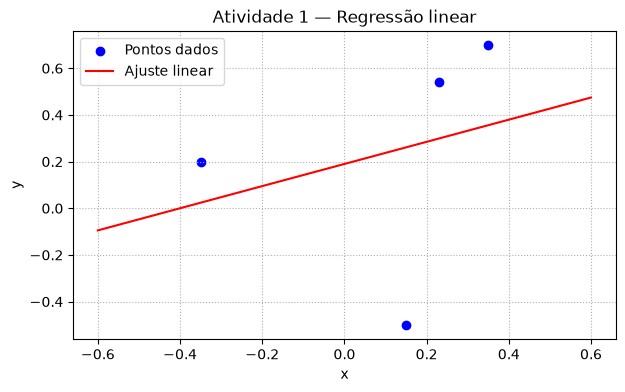

In [2]:
from pathlib import Path
import sys

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / "utils").is_dir():
        sys.path.insert(0, str(candidate))
        break

from utils.algoritmos import regressao

import numpy as np
import matplotlib.pyplot as plt

x1 = np.array([-0.35, 0.15, 0.23, 0.35], dtype=float)
y1 = np.array([0.20, -0.50, 0.54, 0.70], dtype=float)

base_linear = lambda x: np.column_stack((np.ones(len(x)), x))
coef1 = regressao(x1, y1, base_linear)

print("Coeficientes [a1, a2]:", coef1)
print(f"f(x) = {coef1[0]:.8f} + ({coef1[1]:.8f})x")

x_plot = np.linspace(min(x1) - 0.25, max(x1) + 0.25, 400)
y_plot = coef1[0] + coef1[1] * x_plot

plt.figure(figsize=(7, 4))
plt.scatter(x1, y1, color="blue", label="Pontos dados")
plt.plot(x_plot, y_plot, color="red", label="Ajuste linear")
plt.title("Atividade 1 — Regressão linear")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

## Atividade 2 — Regressão linear e cálculo de f(1)

Pontos:

\[
\{(-1.94,1.02),\ (-1.44,0.59),\ (0.93,-0.28),\ (1.39,-1.04)\}
\]

Encontre a função linear \(f(x)=a_1+a_2x\), calcule \(f(1)\) e desenhe o gráfico com os pontos e a reta ajustada.

**Resultados esperados:**

\[
f(x)=-0.06891127-0.53362743x
\]

\[
f(1)=-0.6025387
\]

> Os coeficientes são exibidos na ordem \([a_1,a_2]\), para \(f(x)=a_1+a_2x\).

Coeficientes [a1, a2]: [-0.06891127 -0.53362743]
f(x) = -0.06891127 + (-0.53362743)x
f(1) = -0.60253870


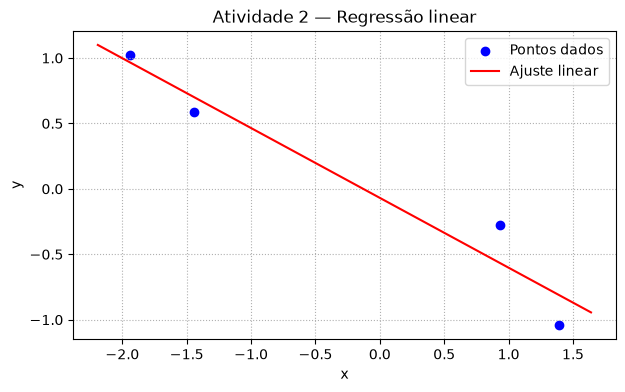

In [3]:
x2 = np.array([-1.94, -1.44, 0.93, 1.39], dtype=float)
y2 = np.array([1.02, 0.59, -0.28, -1.04], dtype=float)

coef2 = regressao(x2, y2, base_linear)
f1 = coef2[0] + coef2[1] * 1

print("Coeficientes [a1, a2]:", coef2)
print(f"f(x) = {coef2[0]:.8f} + ({coef2[1]:.8f})x")
print(f"f(1) = {f1:.8f}")

x_plot = np.linspace(min(x2) - 0.25, max(x2) + 0.25, 400)
y_plot = coef2[0] + coef2[1] * x_plot

plt.figure(figsize=(7, 4))
plt.scatter(x2, y2, color="blue", label="Pontos dados")
plt.plot(x_plot, y_plot, color="red", label="Ajuste linear")
plt.title("Atividade 2 — Regressão linear")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

## Atividade 3 — Ajuste de uma parábola

Encontre a parábola

\[
y=ax^2+bx+c
\]

que melhor aproxima os dados:

| i | 1 | 2 | 3 | 4 | 5 |
|---|---:|---:|---:|---:|---:|
| \(x_i\) | 0.01 | 1.02 | 2.04 | 2.95 | 3.55 |
| \(y_i\) | 1.99 | 4.55 | 7.20 | 9.51 | 10.82 |

**Resultado esperado:**

\[
y=-0.0407898x^2+2.6613293x+1.9364598
\]

Coeficientes [c, b, a]: [ 1.93645978  2.66132929 -0.04078983]
y = -0.04078983x² + (2.66132929)x + (1.93645978)


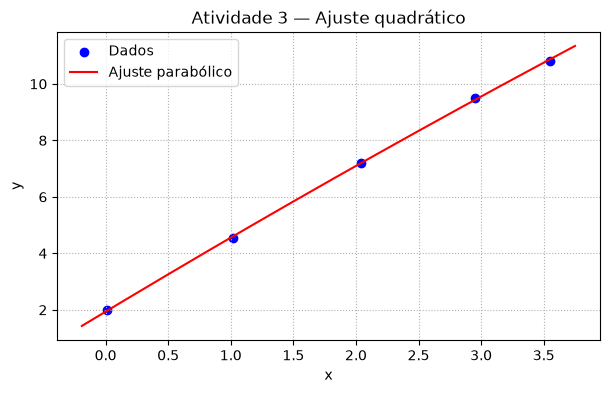

In [4]:
x3 = np.array([0.01, 1.02, 2.04, 2.95, 3.55], dtype=float)
y3 = np.array([1.99, 4.55, 7.20, 9.51, 10.82], dtype=float)

base_quadratica = lambda x: np.column_stack((np.ones(len(x)), x, x**2))
coef3 = regressao(x3, y3, base_quadratica)

print("Coeficientes [c, b, a]:", coef3)
print(f"y = {coef3[2]:.8f}x² + ({coef3[1]:.8f})x + ({coef3[0]:.8f})")

x_plot = np.linspace(min(x3) - 0.2, max(x3) + 0.2, 400)
y_plot = coef3[0] + coef3[1] * x_plot + coef3[2] * x_plot**2

plt.figure(figsize=(7, 4))
plt.scatter(x3, y3, color="blue", label="Dados")
plt.plot(x_plot, y_plot, color="red", label="Ajuste parabólico")
plt.title("Atividade 3 — Ajuste quadrático")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

## Atividade 4 — Ajuste trigonométrico e polinomial

Dados:

| \(x_i\) | 0.0 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| \(y_i\) | 31 | 35 | 37 | 33 | 28 | 20 | 16 | 15 | 18 | 23 | 31 |

### a) Ajuste trigonométrico

Encontre a função

\[
f(x)=a+b\sin(2\pi x)+c\cos(2\pi x)
\]

que melhor aproxima os valores dados.

**Resultados esperados:**

\[
a=25.638625,\quad b=9.8591874,\quad c=4.9751219
\]

### b) Ajuste polinomial de terceiro grau

Encontre a função

\[
f(x)=a+bx+cx^2+dx^3
\]

que melhor aproxima os valores dados.

**Resultados esperados:**

\[
a=31.475524,\quad b=65.691531
\]

\[
c=-272.84382,\quad d=208.23621
\]

Item (a) — [a, b, c]: [25.63862528  9.85918743  4.97512193]


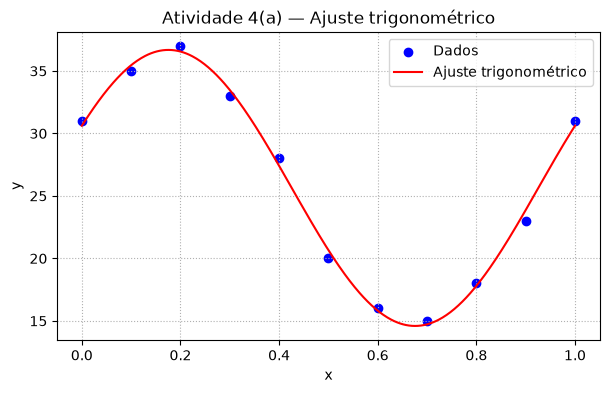

Item (b) — [a, b, c, d]: [  31.47552448   65.69153069 -272.84382284  208.23620824]


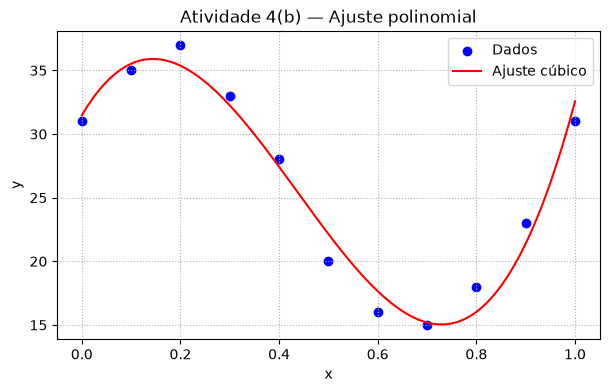

In [5]:
x4 = np.arange(0.0, 1.01, 0.1)
y4 = np.array([31, 35, 37, 33, 28, 20, 16, 15, 18, 23, 31], dtype=float)

# Item (a): base [1, sin(2*pi*x), cos(2*pi*x)]
base_trigonometrica = lambda x: np.column_stack((
    np.ones(len(x)),
    np.sin(2 * np.pi * x),
    np.cos(2 * np.pi * x)
))

coef4a = regressao(x4, y4, base_trigonometrica)
print("Item (a) — [a, b, c]:", coef4a)

x_plot = np.linspace(0, 1, 500)
y_plot_a = (
    coef4a[0]
    + coef4a[1] * np.sin(2 * np.pi * x_plot)
    + coef4a[2] * np.cos(2 * np.pi * x_plot)
)

plt.figure(figsize=(7, 4))
plt.scatter(x4, y4, color="blue", label="Dados")
plt.plot(x_plot, y_plot_a, color="red", label="Ajuste trigonométrico")
plt.title("Atividade 4(a) — Ajuste trigonométrico")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

# Item (b): base [1, x, x², x³]
base_cubica = lambda x: np.column_stack((
    np.ones(len(x)), x, x**2, x**3
))

coef4b = regressao(x4, y4, base_cubica)
print("Item (b) — [a, b, c, d]:", coef4b)

y_plot_b = (
    coef4b[0]
    + coef4b[1] * x_plot
    + coef4b[2] * x_plot**2
    + coef4b[3] * x_plot**3
)

plt.figure(figsize=(7, 4))
plt.scatter(x4, y4, color="blue", label="Dados")
plt.plot(x_plot, y_plot_b, color="red", label="Ajuste cúbico")
plt.title("Atividade 4(b) — Ajuste polinomial")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":")
plt.legend()
plt.show()

## Versionando o código

Depois de concluir as atividades, adicione os arquivos modificados, faça o commit e envie a branch para o servidor:

```bash
git add .
git commit -m "Semana 10"
git push origin semana10
```
